## Importing libraries and unzipping the data

In [3]:
# importing libraries 
import numpy as np                   # for numerical analysis and computations
import pandas as pd                  # for dealing with data frames
import matplotlib.pyplot as plt      # for plotting figures
import shutil as sh                  # for unzipping the dataset
from itertools import product        # for creating the 24 combination in the dataset 
!mv ~/Downloads/ml-latest-small.zip .    # Bash command to move the file from downloads to my working tree
sh.unpack_archive(filename="ml-latest-small.zip", extract_dir="data") # unzipping the dataset

## Remove the unwanted files

In [4]:
!rm ml-latest-small.zip
!rm data/ml-latest-small/README.txt
!rm data/ml-latest-small/links.csv data/ml-latest-small/tags.csv
!path=$(pwd) && mv data/ml-latest-small/ratings.csv $path/data
!path=$(pwd) && mv data/ml-latest-small/movies.csv $path/data
!rm -r data/ml-latest-small/

## Loading the data frames

In [34]:
movies_df = pd.read_csv("data/movies.csv")
ratings_df = pd.read_csv("data/ratings.csv")

## Showing sample of movies data frame

In [35]:
movies_df.head(20)

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


## showing sample of ratings data frame

In [36]:
ratings_df.head(20)

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
5,1,70,3.0,964982400
6,1,101,5.0,964980868
7,1,110,4.0,964982176
8,1,151,5.0,964984041
9,1,157,5.0,964984100


## exploring movies data frame 

In [37]:
movies_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


## exploring ratings data frame

In [38]:
ratings_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


## printing the report 

### Dataset Sparsity

**Total Possible Ratings:**

$$
\text{Total Possible Ratings} =
\text{Unique Users} \times \text{Unique Movies}
$$

**Sparsity Formula:**

$$
\text{Sparsity} =
\left(1 - \frac{\text{Actual Ratings}}{\text{Total Possible Ratings}}\right)
\times 100
$$

**Where:**
- **Unique Users:** Number of distinct users in the dataset.
- **Unique Movies:** Number of distinct movies in the dataset.
- **Actual Ratings:** Total number of existing ratings in the dataset.
- **Total Possible Ratings:** Maximum number of ratings if every user rated every movie.

**Interpretation:**
- Higher sparsity means a larger percentage of user–movie combinations have missing ratings.
- Lower sparsity means the rating matrix contains more observed ratings.
- A sparsity of $0\%$ means every user has rated every movie.
- A sparsity close to $100\%$ means most user–movie combinations have missing ratings.

In [39]:
#defining the variables 
unique_users = ratings_df["userId"].nunique()
unique_movies = movies_df["movieId"].nunique()
unique_rated_movies = ratings_df["movieId"].nunique()
ratings = ratings_df["rating"].count()
all_ratings = unique_users * unique_movies
sparisty = (1 - (ratings / all_ratings)) * 100
# 1- 100836/(610*9742)

# unique --> get the unique values in a series 
# nunique --> count the unique values in a series 
# count --> count the number of non nan values in a series

#printing the results 
print("Number of unique users in the dataset --> ", unique_users)
print("Number of unique movies (rated and unrated) --> ", unique_movies)
print("Number of unique movies that have been rated --> ", unique_rated_movies)
print("Number of ratings in the dataset -->", ratings)
print("number of pairs of users and movies that have no ratings --> ", round(sparisty, 2), "%")
print("Number of pairs of users and movies that have ratings --> ", round(100-sparisty,2),"%")

Number of unique users in the dataset -->  610
Number of unique movies (rated and unrated) -->  9742
Number of unique movies that have been rated -->  9724
Number of ratings in the dataset --> 100836
number of pairs of users and movies that have no ratings -->  98.3 %
Number of pairs of users and movies that have ratings -->  1.7 %


## Creating the user movie data frame 

In [40]:
user_movie_df = pd.pivot_table(
    data = ratings_df,   # --> using rating_df not movies_df because rating_df contain both movies and user id 
    index = "userId",    # --> rows of the data frame 
    columns = "movieId", # --> columns of the data frame
    values = "rating",   # --> content of the data frame 
    fill_value = pd.NA)  # --> fill the values of the missing content with pd.NA (98.3% of the table)

## Showing a sample of user_moview data frame

In [41]:
user_movie_df.head(20)

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,3.0,5.0,4.0,4.0,3.0,NaN,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## exploring the data frame 

In [42]:
user_movie_df.info()
print("Dimensions of the data frame --> ", user_movie_df.shape)
# shape --> (number of unique users , number of unique movies)

<class 'pandas.DataFrame'>
Index: 610 entries, 1 to 610
Columns: 9724 entries, 1 to 193609
dtypes: float64(9724)
memory usage: 45.3 MB
Dimensions of the data frame -->  (610, 9724)


## plotting the ditribution of the ratings 

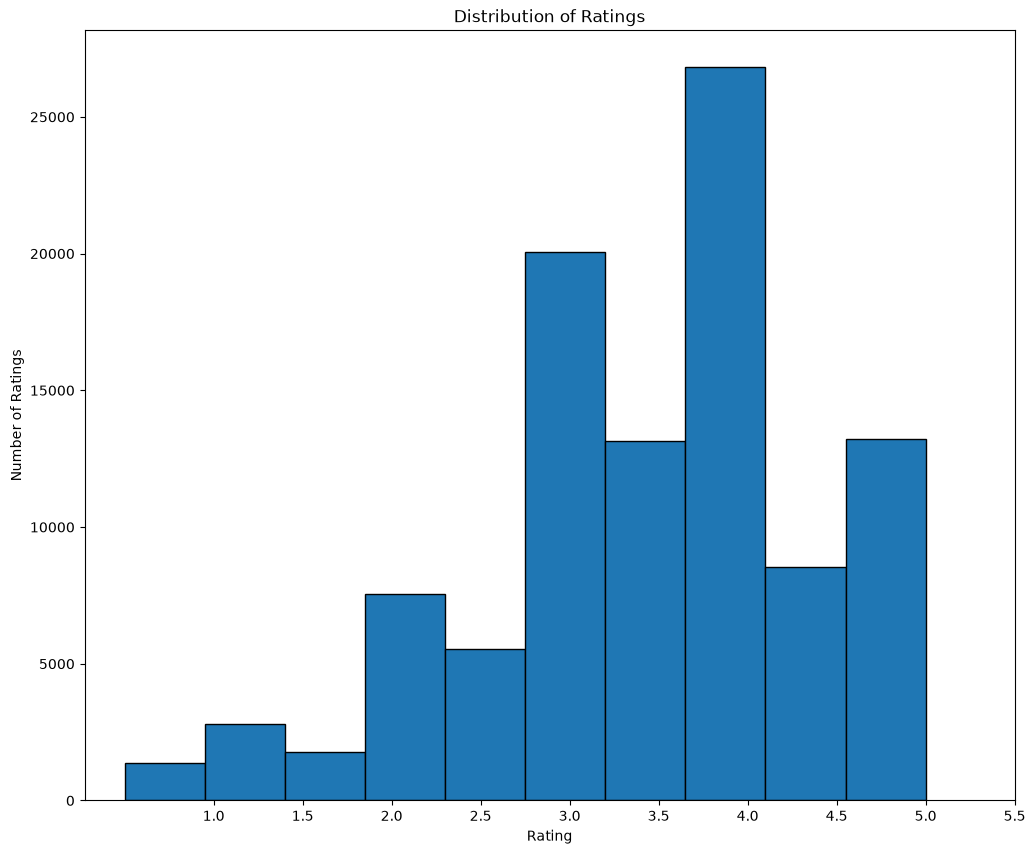

In [43]:
# How many time each rating is repeated 
# How the 100836 ratings are distributed among te rating values
plt.figure(figsize=(12, 10))
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.hist(ratings_df["rating"], bins=10, edgecolor="black")
plt.xticks(np.arange(1, 6, 0.5)) # divide the x axis (1 , 1.5 , 2 , 2.5 .. , 6)
plt.show()

## plot the number of the ratings of each user

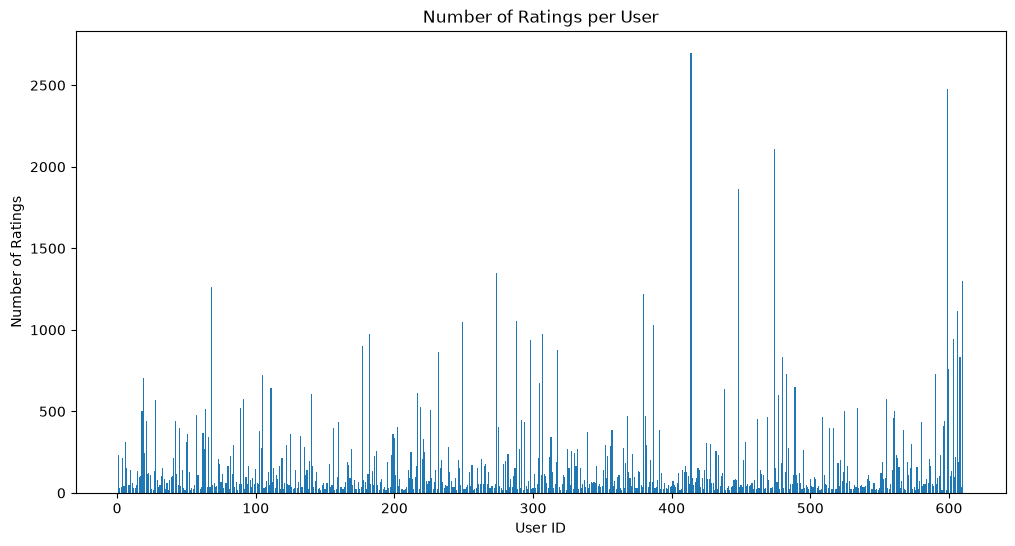

In [44]:
plt.figure(figsize=(12, 6))
ratings_per_user = ratings_df.groupby("userId")["rating"].count()
plt.bar(ratings_per_user.index, ratings_per_user.values)
plt.title("Number of Ratings per User")
plt.xlabel("User ID")
plt.ylabel("Number of Ratings")
plt.show()
# rating_per_user.index --> refers to the user id in the grouped data frame 
# ratinf_per_user.values --> number of the ratings each user made
# .count() --> counts the non nan values in a series

# implementing get_co_rated function
---

In [45]:
def get_co_rated (matrix_values , a_idx , b_idx , axis) :
    if axis == "index" :
        a_rated = matrix_values[a_idx,:]
        b_rated = matrix_values[b_idx,:]
    elif axis =="columns" :
        a_rated = matrix_values[:,a_idx]
        b_rated = matrix_values[:,b_idx]
    common_indeces = ~np.isnan(a_rated) & ~np.isnan(b_rated)
    a_rated = a_rated[common_indeces]
    b_rated = b_rated[common_indeces]
    return a_rated , b_rated

## Testing the previous function 

In [46]:
matrix_values_for_testing = user_movie_df.to_numpy()
print(matrix_values_for_testing.shape)
print("-"*40)
a_rated, b_rated = get_co_rated(matrix_values_for_testing, 2, 3, axis="index")
print(a_rated , "\n" , b_rated)
print("-"*40)
a_rated, b_rated = get_co_rated(matrix_values_for_testing, 1, 2, axis="columns")
print(a_rated , "\n" ,b_rated)

(610, 9724)
----------------------------------------
[0.5] 
 [5.]
----------------------------------------
[4.  3.  4.5 2.5 3.  3.  4.  2.  3.  5.  2.  3.  2.5 3.  5.  1.5 3.  3.
 3.  4.  3.  3.  2.5 4.  2.5 2. ] 
 [5.  3.  4.  2.  3.  3.  5.  1.  3.5 4.  4.  1.  3.5 0.5 3.  3.  4.  3.
 3.  3.  2.5 5.  3.  4.  1.5 2. ]


# Implementing similarity metrics
---

### Euclidean Distance and Similarity

**Euclidean Distance Formula:**

$$
d(vec1, vec2) = \sqrt{\sum_{i=1}^{n}(vec1_i - vec2_i)^2}
$$

**Euclidean Similarity Formula:**

$$
\operatorname{Similarity}(vec1, vec2) = \frac{1}{1 + d(vec1, vec2)}
$$

**Interpretation:**
- Smaller distance indicates greater similarity.
- Larger distance indicates lower similarity.
- relation between similarity and distance are inversely proportional 
- Similarity ranges from $(0,1]$.
- If the vectors are identical, the distance is $0$ and the similarity is $1$.

In [47]:
def eucledian_similarity(vec1,vec2):
    vec1 = np.array(vec1, dtype=float)
    vec2 = np.array(vec2,dtype = float)
    distance = np.linalg.norm(vec1 - vec2)
    similarity = 1.0 / (1.0+distance)
    return similarity

### Cosine Similarity

Cosine similarity measures the cosine of the angle between two vectors, `vec1` and `vec2`. It compares their directions rather than their magnitudes.

**Formula:**

$$
\operatorname{Similarity}(vec1, vec2) =
\frac{vec1 \cdot vec2}{\|vec1\|\|vec2\|}
$$

**Interpretation:**
- A value close to $1$ indicates similar vector directions means that `theta = 0`
- A value close to $0$ indicates orthogonal vectors means that `theta = 90`
- A value close to $-1$ indicates opposite vector directions means that `theta = 180`
- relation between the `cos theta` anf `theta` are inversley proportional
- The similarity range is $[-1,1]$.

In [48]:
def cosine_similarity(vec1,vec2):
    vec1 = np.array(vec1, dtype=float)
    vec2 = np.array(vec2, dtype=float)
    numerator = np.dot(vec1,vec2)
    norm1 = np.linalg.norm(vec1)
    norm2 = np.linalg.norm(vec2)
    denemenator = norm1 * norm2
    if denemenator == 0 :
        return 0.0
    similarity = numerator /denemenator
    return similarity

### Pearson Correlation Similarity Using the Cosine Formula

Pearson correlation can be calculated using the cosine similarity formula after subtracting the mean of each vector from its elements.

**Step 1: Calculate the mean of each vector.**

$$
\overline{vec1} = \frac{1}{n}\sum_{i=1}^{n} vec1_i
$$

$$
\overline{vec2} = \frac{1}{n}\sum_{i=1}^{n} vec2_i
$$

**Step 2: Center both vectors by subtracting their respective means.**

$$
vec1_{\text{centered}} = vec1 - \overline{vec1}
$$

$$
vec2_{\text{centered}} = vec2 - \overline{vec2}
$$

**Step 3: Apply the cosine similarity formula to the centered vectors.**

$$
\operatorname{Pearson}(vec1, vec2) =
\frac{vec1_{\text{centered}} \cdot vec2_{\text{centered}}}
{\|vec1_{\text{centered}}\|\|vec2_{\text{centered}}\|}
$$


**Interpretation:**
- A value close to $1$ indicates similar rating patterns. 
- A value close to $0$ indicates little or no linear correlation.
- A value close to $-1$ indicates opposite rating patterns.

How vectors are similar respect to their average rating

In [49]:
def  pearson_similarity (vec1,vec2) :
    vec1 = np.array(vec1 , dtype=float)
    vec2 = np.array(vec2 , dtype= float)
    mean1 = np.mean(vec1)
    mean2 = np.mean(vec2)
    vec1 = vec1 - mean1 
    vec2 = vec2 - mean2 
    similarity = cosine_similarity(vec1,vec2)
    return similarity

## Testing the previous function

In [50]:
vec1 =  [5, 4, 5, 3]
vec2 =  [3 , 2, 3, 1]
print("eucledian_similarity --> " ,eucledian_similarity(vec1,vec2) )
print("cosine_similarity -->  ", cosine_similarity(vec1,vec2))
print("Pearson similarity --> " ,pearson_similarity(vec1,vec2) )

eucledian_similarity -->  0.2
cosine_similarity -->   0.9871639953033075
Pearson similarity -->  1.0


#### Creating a dictionary for index and id for the movies and user for numpy accessing 
---

In [ ]:
# Not used but only for testing the idea of mapping index using dictionary 
# the real dictionary is created below for the training data only 
movie_id_to_index= {}
movie_index_to_id= {}
for movie_index , movie_id in enumerate(user_movie_df.columns):
    movie_id_to_index[movie_id]=movie_index
    movie_index_to_id[movie_index]=movie_id

user_id_to_index ={}
user_index_to_id ={}
for user_index , user_id in enumerate(user_movie_df.index):
    user_id_to_index[user_id]= user_index
    user_index_to_id[user_index] = user_id

#### Testing the previous dictionaries 

In [58]:
# Testing the movies dictionary
print(movie_index_to_id[100])
print(movie_id_to_index[113])
# Testing the user dictionary
print(user_index_to_id[600])
print(user_id_to_index[601])


113
100
601
600


## implementing the user collaborative filtering 
- User-based CF: find users similar to the target user, then predict a rating as a weighted average of what those similar users rated the target item
- see similar users 
- see how they rated the target movie x
---

$$
\text{Predicted Rating} =
\frac{\sum (\text{Similarity} \times \text{Rating})}
{\sum |\text{Similarity}|}
$$

**Important notes:**
- Only neighbors who have rated the target movie contribute to the prediction.
- The denominator uses the absolute values of similarities to prevent positive and negative similarities from canceling each other out.
- If the denominator is zero, the prediction cannot be calculated using this formula.
- If fewer than $k$ eligible neighbors are available, all eligible neighbors are used.

In [59]:
def find_k_nearest_users(matrix_values : np.ndarray , target_user_id , k , similarity_function , target_movie_id =None):

    # definig variables each element in similarity or top_k_similarity (user_id,similarity value)
    similarities = []
    top_k_similarities = []
    
    # Convert the user id from id to index so we can use in numpy array accessing 
    if target_user_id not in user_id_to_index : return [],[]
    target_user_index = user_id_to_index[target_user_id]

    # Convert the movie id from id to index + filtering the user if the movie id is provided
    if target_movie_id is not None : 
        if target_movie_id not in movie_id_to_index : return [] , []
        target_movie_index = movie_id_to_index[target_movie_id]
        # Filtering the candidate users (users only who rated the target movie) to decrease excution time
        candiadte_users = np.where(~np.isnan(matrix_values[: , target_movie_index]))[0]
    else :
        candiadte_users = range(matrix_values.shape[0])

    # Loop through the candindate user 
    # in case of movie id provided -- > they are small subset of all users bec of filtering
    # in case of movie id not provided --> they are all the users
    for user_index in candiadte_users :
        if user_index == target_user_index :
            continue
        a_rated , b_rated = get_co_rated(matrix_values , target_user_index , user_index , axis="index")
        if len(a_rated) >=2 :
            similarity = similarity_function(a_rated , b_rated)
            if np.isfinite(similarity) :
                user_id = user_index_to_id[user_index]
                similarities.append((user_id , similarity))
    similarities.sort(key=lambda x:x[1] , reverse=True)
    top_k_similarities = similarities[:k]
    return top_k_similarities , similarities

                

def predict_rating_user_based(matrix_values:np.ndarray , target_user_id , target_movie_id , k , similarity_function  , mode) :

    # check if the target id and the movie id are valid 
    if target_user_id not in user_id_to_index or  target_movie_id not in movie_id_to_index :
        return None
    target_user_index = user_id_to_index[target_user_id]
    target_movie_index = movie_id_to_index[target_movie_id]

    # send the target movie based on the mode (without filter --> slower computations)
    if mode =="filter before finding the neighbours" :
       top_k_similarities , similarities = find_k_nearest_users(matrix_values,target_user_id,k,similarity_function , target_movie_id)
    elif mode =="without filter" :
        top_k_similarities , similarities= find_k_nearest_users(matrix_values, target_user_id , k, similarity_function)

    # If there are no neighbours found because of the length of get co rated vector 
    if not top_k_similarities :
        return None

    numerator = 0
    denemenator =0
    for user_id , similarity in top_k_similarities :
        user_index = user_id_to_index[user_id]
        rating = matrix_values[user_index,target_movie_index]
        if np.isnan(rating):
            continue 
        numerator+= rating*similarity
        denemenator+= abs(similarity)
    predicted_rating = numerator/denemenator if denemenator != 0 else None
    return predicted_rating 

## Implementing item based collaborative filtering

- Item-based CF: find items similar to the target item (based on how users rated them), then predict a rating as a weighted average of how the target user rated those similar items
- get similar movies to the target movie 
- see how the target user rated them 
---

In [60]:
def find_k_nearest_movies( matrix_values: np.ndarray, target_movie_id, k, similarity_function, target_user_id=None):

    # defining variables; each element in similarities or top_k_similarities is (movie_id, similarity value)
    similarities = []
    top_k_similarities = []

    # Convert the movie id from id to index so we can use it in NumPy array accessing
    if target_movie_id not in movie_id_to_index:
        return [], []
    target_movie_index = movie_id_to_index[target_movie_id]

    # Convert the user id from id to index if the user id is provided
    # Filtering the candidate movies (movies rated by the target user) to decrease execution time
    if target_user_id is not None:
        if target_user_id not in user_id_to_index:
            return [], []
        target_user_index = user_id_to_index[target_user_id]
        # Consider only movies that the target user has rated
        candidate_movies = np.where(~np.isnan(matrix_values[target_user_index, :]))[0]
    else:
        # If no user id is provided, consider all movies
        candidate_movies = range(matrix_values.shape[1])

    # Loop through the candidate movies
    # In case of user id provided --> they are a subset of all movies because of filtering
    # In case of user id not provided --> they are all the movies
    for movie_index in candidate_movies:

        # Skip the target movie
        if movie_index == target_movie_index:
            continue

        # Get the ratings of users who rated both movies
        a_rated, b_rated = get_co_rated( matrix_values, target_movie_index, movie_index,axis="columns")

        # At least two users must have rated both movies
        if len(a_rated) >= 2:
            similarity = similarity_function(a_rated, b_rated)
            if np.isfinite(similarity):
                movie_id = movie_index_to_id[movie_index]
                similarities.append((movie_id, similarity))

    # Sort the movies based on similarity in descending order
    similarities.sort(key=lambda x: x[1], reverse=True)
    top_k_similarities = similarities[:k]
    return top_k_similarities, similarities


def predict_rating_movie_based( matrix_values: np.ndarray , target_user_id, target_movie_id,k, similarity_function, mode):

    # Check if the target user id and movie id are valid
    if target_user_id not in user_id_to_index or target_movie_id not in movie_id_to_index:
        return None
    # Convert the user id and movie id from IDs to indices
    target_user_index = user_id_to_index[target_user_id]
    target_movie_index = movie_id_to_index[target_movie_id]

    # Find the nearest movies based on the selected mode
    # In the first mode, consider only movies rated by the target user
    # In the second mode, consider all movies
    if mode == "filter before finding the neighbours":
        top_k_similarities, similarities = find_k_nearest_movies(matrix_values,target_movie_id,k,similarity_function,target_user_id)
    elif mode == "without filter":
        top_k_similarities, similarities = find_k_nearest_movies(matrix_values,target_movie_id,k,similarity_function)

    # If there are no neighbours found because of insufficient co-rated users because of the length of vector
    if not top_k_similarities:
        return None

    numerator = 0
    denominator = 0

    # Calculate the predicted rating using the nearest movies
    for movie_id, similarity in top_k_similarities:

        movie_index = movie_id_to_index[movie_id]
        rating = matrix_values[target_user_index, movie_index]
        # If the target user has not rated this movie, skip it
        if np.isnan(rating):
            continue

        numerator += rating * similarity
        denominator += abs(similarity)

    predicted_rating = numerator / denominator if denominator != 0 else None
    return predicted_rating

## Implement function to split the data
---
### Train-Test Split Formulas

For each user:

1. **Total Number of Samples**
   
   $$N_{\text{total}} = \text{Number of ratings given by the user}$$

2. **Number of Testing Samples**
   
   $$N_{\text{test}} = \lfloor N_{\text{total}} \times \text{test\_size} \rfloor$$

3. **Number of Training Samples**
   
   $$N_{\text{train}} = N_{\text{total}} - N_{\text{test}}$$

In [61]:
def train_test_split_ratings(ratings_df: pd.DataFrame, test_size=0.2):
    training_set = None
    testing_set = None
    for user , movie_ratings in ratings_df.groupby("userId"):
        number_of_user_ratings = len(movie_ratings)
        number_of_test_samples = int(number_of_user_ratings * test_size)
        number_of_train_samples = number_of_user_ratings - number_of_test_samples
        shuffled_movie_ratings = movie_ratings.sample(frac=1, random_state=42)
        user_training_set = shuffled_movie_ratings.iloc[:number_of_train_samples]
        user_testing_set = shuffled_movie_ratings.iloc[number_of_train_samples:]
        if training_set is None:
            training_set = user_training_set
            testing_set = user_testing_set
        else:
            training_set = pd.concat([training_set, user_training_set])
            testing_set = pd.concat([testing_set, user_testing_set])
    training_set = training_set.sample(frac=1, random_state=42)
    testing_set = testing_set.sample(frac=1, random_state=42)
    return training_set, testing_set
    

## Implement evaluate function
---
### Evaluation Metrics

**1. Root Mean Squared Error (RMSE)**

$$
RMSE = \sqrt{\frac{1}{M}\sum_{i=1}^{M}(y_i-\hat{y}_i)^2}
$$

**2. Mean Absolute Error (MAE)**

$$
MAE = \frac{1}{M}\sum_{i=1}^{M}|y_i-\hat{y}_i|
$$

**Interpretation:**
- Lower RMSE and MAE values indicate better prediction accuracy.
- RMSE penalizes larger prediction errors more heavily than MAE because it is squared.
- Both metrics are calculated using only successful predictions.
- RMSE is better because it is differentiable function which can be used in minimizing the error

In [62]:
def evaluate( matrix_values: np.ndarray, test_df: pd.DataFrame , k, similarity_function, method,mode):

    # Check whether the selected method is valid
    if method not in ("user_based", "item_based"):
        raise ValueError("method must be 'user_based' or 'item_based'")

    # Check whether the selected mode is valid
    if mode not in ("filter before finding the neighbours", "without filter"):
        raise ValueError(
            "mode must be 'filter before finding the neighbours' or 'without filter'")

    # Store successful predictions as (actual_rating, predicted_rating) pairs
    predictions = []
    # Count test samples for which the model cannot produce a prediction
    impossible_predictions = 0

    # Iterate over every rating in the test set
    for _, row in test_df.iterrows():

        # Extract the user ID, movie ID, and actual rating
        user_id = row["userId"]
        movie_id = row["movieId"]
        actual_rating = row["rating"]

        # Generate a prediction using the selected collaborative filtering method
        if method == "user_based":
            predicted_rating = predict_rating_user_based(matrix_values,user_id,movie_id,k,similarity_function,mode)
        else: 
            predicted_rating = predict_rating_movie_based(matrix_values,user_id,movie_id,k,similarity_function,mode)

        # Store successful predictions and count impossible predictions
        if predicted_rating is not None and np.isfinite(predicted_rating):
            predictions.append((actual_rating, predicted_rating))
        else:
            impossible_predictions += 1

    # Count the total number of ratings in the test set
    total_test_ratings = len(test_df)
    # Calculate the fraction of impossible predictions
    impossible_fraction = impossible_predictions / total_test_ratings if total_test_ratings > 0 else None

    # If no predictions were successful, RMSE and MAE cannot be calculated
    if len(predictions) == 0:
        return {
            "RMSE": None,
            "MAE": None,
            "impossible_fraction": impossible_fraction,
            "successful_predictions": 0,
            "impossible_predictions": impossible_predictions}

    # RMSE AND MAE calculation
    # Convert actual and predicted ratings into NumPy arrays
    actual_ratings = np.array([p[0] for p in predictions])
    predicted_ratings = np.array([p[1] for p in predictions])
    # Calculate Root Mean Squared Error (RMSE)
    rmse = np.sqrt(np.mean((actual_ratings - predicted_ratings) ** 2))
    # Calculate Mean Absolute Error (MAE)
    mae = np.mean(np.abs(actual_ratings - predicted_ratings))

    # Return all evaluation metrics
    return {
        "RMSE": rmse,
        "MAE": mae,
        "impossible_fraction": impossible_fraction,
        "successful_predictions": len(predictions),
        "impossible_predictions": impossible_predictions}

In [ ]:
# Split the dataset for each user
train_df, test_df = train_test_split_ratings(ratings_df, test_size=0.2)
# Create a pivot table using the training dataset only to prevent data leakage --> test_df will be sent as a separate argument
train_user_movie_df = pd.pivot_table(data=train_df,index="userId",columns="movieId",values="rating",fill_value=np.nan)
# Convert the pivot table into a NumPy 2D array for faster indexing
matrix_values = train_user_movie_df.to_numpy(dtype=float)

# Creating a dictionary mapping index to id and viceversa for faster numpy accessing
movie_id_to_index= {}
movie_index_to_id= {}
for movie_index , movie_id in enumerate(train_user_movie_df.columns):
    movie_id_to_index[movie_id]=movie_index
    movie_index_to_id[movie_index]=movie_id

user_id_to_index ={}
user_index_to_id ={}
for user_index , user_id in enumerate(train_user_movie_df.index):
    user_id_to_index[user_id]= user_index
    user_index_to_id[user_index] = user_id

# Define the parameters for evaluation:
# 2 methods * 3 similarity functions * 4 k values = 24 combinations
methods = ["user_based", "item_based"]
similarity_functions = {
    "euclidean": eucledian_similarity,
    "cosine": cosine_similarity,
    "pearson": pearson_similarity}
k_values = [5, 10, 20, 50]
modes = ["filter before finding the neighbours","without filter"]

# Store the evaluation results
results = []

# Generate all combinations of method, similarity function, k, and mode]  =filter before neighbours
for method, (sim_name, sim_fn), k in product(methods,similarity_functions.items(),k_values):
    # Evaluate the model using the current combination of parameters
    evaluation = evaluate(matrix_values, test_df,k,sim_fn,method,modes[0])

    # Store the results in a dictionary
    result = {
        "Method": method,
        "Similarity": sim_name,
        "k": k,
        "Mode": modes[0],
        "RMSE": evaluation["RMSE"],
        "MAE": evaluation["MAE"],
        "Impossible %": (
            f"{evaluation['impossible_fraction']:.2%}"
            if evaluation["impossible_fraction"] is not None
            else None),
        "Successful Predictions": evaluation["successful_predictions"],
        "Impossible Predictions": evaluation["impossible_predictions"]}

    # Add the current result to the results list
    results.append(result)

    # printing the progress
    print(
        f"Done: Method={method} | Sim={sim_name} | k={k} | "
        f"RMSE={round(evaluation['RMSE'],4)}")
results_df = pd.DataFrame(results)

Done: Method=user_based | Sim=euclidean | k=5 | RMSE=1.0055
Done: Method=user_based | Sim=euclidean | k=10 | RMSE=0.9764
Done: Method=user_based | Sim=euclidean | k=20 | RMSE=0.9658
Done: Method=user_based | Sim=euclidean | k=50 | RMSE=0.9652
Done: Method=user_based | Sim=cosine | k=5 | RMSE=1.0106
Done: Method=user_based | Sim=cosine | k=10 | RMSE=0.9823
Done: Method=user_based | Sim=cosine | k=20 | RMSE=0.9721
Done: Method=user_based | Sim=cosine | k=50 | RMSE=0.9711
Done: Method=user_based | Sim=pearson | k=5 | RMSE=1.2628
Done: Method=user_based | Sim=pearson | k=10 | RMSE=1.3253
Done: Method=user_based | Sim=pearson | k=20 | RMSE=1.4379
Done: Method=user_based | Sim=pearson | k=50 | RMSE=1.6788
Done: Method=item_based | Sim=euclidean | k=5 | RMSE=0.9812
Done: Method=item_based | Sim=euclidean | k=10 | RMSE=0.9396
Done: Method=item_based | Sim=euclidean | k=20 | RMSE=0.9185
Done: Method=item_based | Sim=euclidean | k=50 | RMSE=0.9127
Done: Method=item_based | Sim=cosine | k=5 | RMS

In [69]:
results_df

,Method,Similarity,k,Mode,RMSE,MAE,Impossible %,Successful Predictions,Impossible Predictions
0,user_based,euclidean,5,filter before finding the neighbours,1.005543,0.771827,4.35%,19072,868
1,user_based,euclidean,10,filter before finding the neighbours,0.976445,0.748724,4.35%,19072,868
2,user_based,euclidean,20,filter before finding the neighbours,0.965817,0.741618,4.35%,19072,868
3,user_based,euclidean,50,filter before finding the neighbours,0.965241,0.743676,4.35%,19072,868
4,user_based,cosine,5,filter before finding the neighbours,1.010559,0.776336,4.35%,19072,868
5,user_based,cosine,10,filter before finding the neighbours,0.982268,0.753932,4.35%,19072,868
6,user_based,cosine,20,filter before finding the neighbours,0.972080,0.748584,4.35%,19072,868
7,user_based,cosine,50,filter before finding the neighbours,0.971118,0.751171,4.35%,19072,868
8,user_based,pearson,5,filter before finding the neighbours,1.262790,0.876230,4.41%,19060,880
9,user_based,pearson,10,filter before finding the neighbours,1.325253,0.905479,4.41%,19060,880


In [70]:
#Generate all combinations of method, similarity function, k, and mode =without filter
for method, (sim_name, sim_fn), k in product(methods,similarity_functions.items(),k_values):
    # Evaluate the model using the current combination of parameters
    evaluation = evaluate(matrix_values, test_df,k,sim_fn,method,modes[1])

    # Store the results in a dictionary
    result = {
        "Method": method,
        "Similarity": sim_name,
        "k": k,
        "Mode": modes[1],
        "RMSE": evaluation["RMSE"],
        "MAE": evaluation["MAE"],
        "Impossible %": (
            f"{evaluation['impossible_fraction']:.2%}"
            if evaluation["impossible_fraction"] is not None
            else None),
        "Successful Predictions": evaluation["successful_predictions"],
        "Impossible Predictions": evaluation["impossible_predictions"]}

    # Add the current result to the results list
    results.append(result)

    # printing the progress
    print(
        f"Done: Method={method} | Sim={sim_name} | k={k} | "
        f"RMSE={round(evaluation['RMSE'],4)}")
results_df = pd.DataFrame(results)

Done: Method=user_based | Sim=euclidean | k=5 | RMSE=1.1801
Done: Method=user_based | Sim=euclidean | k=10 | RMSE=1.1599
Done: Method=user_based | Sim=euclidean | k=20 | RMSE=1.156
Done: Method=user_based | Sim=euclidean | k=50 | RMSE=1.1344
Done: Method=user_based | Sim=cosine | k=5 | RMSE=1.2333
Done: Method=user_based | Sim=cosine | k=10 | RMSE=1.223
Done: Method=user_based | Sim=cosine | k=20 | RMSE=1.2072
Done: Method=user_based | Sim=cosine | k=50 | RMSE=1.1462
Done: Method=user_based | Sim=pearson | k=5 | RMSE=1.3022
Done: Method=user_based | Sim=pearson | k=10 | RMSE=1.2745
Done: Method=user_based | Sim=pearson | k=20 | RMSE=1.2713
Done: Method=user_based | Sim=pearson | k=50 | RMSE=1.1541
Done: Method=item_based | Sim=euclidean | k=5 | RMSE=1.1298
Done: Method=item_based | Sim=euclidean | k=10 | RMSE=1.0994
Done: Method=item_based | Sim=euclidean | k=20 | RMSE=1.0656
Done: Method=item_based | Sim=euclidean | k=50 | RMSE=1.0317
Done: Method=item_based | Sim=cosine | k=5 | RMSE=

KeyboardInterrupt: 

---
# AI helped us with:
- Improving get_co_rated: AI suggested changing it to accept a 2D NumPy array instead of a DataFrame, since NumPy allows faster indexing than using Pandas .loc.
- Creating the four dictionaries: Based on this idea, we created four dictionaries to map each user and movie ID to its corresponding index, and vice versa, so we could access the ratings directly using NumPy arrays.
- Updating the functions: We modified all the functions to accept a 2D NumPy array and use the dictionaries internally to convert user and movie IDs into their corresponding indices.
- Simplifying the grid search: AI recommended using the itertools library and its product() function instead of writing three nested loops to test all the possible combinations.
- Writing the mathematical formulas: AI helped us write the mathematical formulas for the similarity functions and evaluation metrics inside the Markdown cells.
- No cell was fully generated using AI. We used AI to look up specific methods, understand what they do and how to use them, explore the logic behind implementing specific functionalities, and improve the English formatting and wording of our Markdown cells.

---
# Part A what did we notice from plots
What we noticed from the plots:

1. Distribution of Ratings:

Most ratings are on the high side: People generally don't bother rating movies they hate. A 4.0 or a 3.0 pops up way more often than anything else, and low scores (like 1s) are pretty rare.
Whole numbers win: Users seem to prefer regular numbers (like 3.0 or 4.0) over half-stars (like 3.5 or 4.5).
The takeaway: Since people mostly rate stuff they chose to watch, they tend to like it. But it also highlights the "generous vs. harsh rater" problem—some people hand out 5s easily while others are strict, which is why plain Euclidean distance fails us here.

2. Number of Ratings per User:

Super uneven activity: You can see a few massive movie buffs who rated thousands of films, but the vast majority of users only have a handful or a few hundred ratings.
High sparsity: Because everyone has only watched a tiny fraction of the whole movie list, the matrix is mostly empty.
The takeaway: Any two random users won't share many movies in common. That's exactly why we have to filter for co-rated items and skip any user pairs that share fewer than two movies.

--- 
# part F analysis
#### Best Similarity Metric: Results vs. Intuition   (With filtering approach)

Based on our results, **Euclidean similarity performed best overall** among the three similarity metrics we tested
The lowest RMSE was achieved by **item-based collaborative filtering using Euclidean similarity with 50 neighbors**, reaching an RMSE of 0.9127. Euclidean also achieved lower RMSE than cosine and Pearson for the corresponding values of k in both user-based and item-based collaborative filtering.

### Does Our Results Match the Intuition from Section 3.2?

No. The intuition from Section 3.2 suggests that Pearson correlation should perform best because it accounts for differences in users' rating habits by comparing how their ratings vary relative to their individual averages. However, our results show that Euclidean similarity performed better than Pearson.


There are several possible reasons for this disagreement:

- **Few co-rated movies:** When two users have rated only two or three movies in common, Pearson correlation can produce extreme values, such as +1 or -1, even when there is not enough data to establish a reliable relationship. This makes the similarity estimates noisy
euceledian produces only number between 0 and 1 but difficult to produce 1 because distance between 2 vectors cant be 0 unless they are the same vector
pearson can produce 1 if user A have ratings(5,4) and user B have ratings of(4,3) which is not enough to say that the users are exactly similar and our data contains alot of nan values which supports this claim 


- **Negative similarities:** Pearson correlation can produce negative similarity values. As we increase k, the selected neighbors may include more negatively correlated users or movies. Since our prediction formula uses raw ratings rather than mean-centered ratings, these neighbors can negatively affect the predicted rating.
negatively collerated neighbours contributes by decreasing the numerator which may affect the prediction

- **Dataset characteristics:** The MovieLens dataset may not exhibit the same generous-versus-harsh rating behavior as the example in Section 3.2. If differences in users' average ratings are less problematic in our data, Pearson's ability to account for those differences may provide less of an advantage.

Therefore, although Pearson correlation can be more appropriate when users have different rating baselines, it did not perform best in our experiments. The results depend on the dataset, the available co-rated items, and how the prediction formula uses the similarity scores.

---

## Example Where Euclidean and Pearson Rank Users Differently

Consider two users who rated four movies:
We will compare the users using Euclidean distance and Pearson correlation.

| Movie | User A | User B |
|---|---:|---:|
| Movie 1 | 1 | 3 |
| Movie 2 | 2 | 4 |
| Movie 3 | 3 | 5 |
| Movie 4 | 4 | 1 |



### Euclidean Distance

Euclidean distance measures the absolute differences between the ratings.

The differences are:

- Movie 1: 1 - 3 = -2
- Movie 2: 2 - 4 = -2
- Movie 3: 3 - 5 = -2
- Movie 4: 4 - 1 = 3

The squared differences are 4, 4, 4, and 9.

The Euclidean distance is:
Distance = sqrt(4 + 4 + 4 + 9) = sqrt(21) ≈ 4.583
Using the similarity function implemented in our project:
Similarity = 1 / (1 + Distance)
Euclidean similarity = 1 / (1 + 4.583) ≈ 0.179
This indicates relatively low similarity because the users' ratings differ considerably in absolute value.

### Pearson Correlation

Pearson correlation measures how similarly two users' ratings vary relative to their respective average ratings.
User A's average rating is 2.5.
User B's average rating is 3.25.
After subtracting each user's average from their ratings, we obtain:

| Movie | User A deviation | User B deviation |
|---|---:|---:|
| Movie 1 | -1.5 | -0.25 |
| Movie 2 | -0.5 | 0.75 |
| Movie 3 | 0.5 | 1.75 |
| Movie 4 | 1.5 | -2.25 |

Using the Pearson correlation formula, the correlation is approximately -0.134.

This indicates a weak negative linear relationship between the users' rating patterns.

### Comparison

- Euclidean similarity is approximately `0.179`.
- Pearson correlation is approximately `-0.134`.

These values illustrate that Euclidean similarity and Pearson correlation use different criteria: Euclidean measures absolute rating differences, while Pearson measures the strength and direction of a linear relationship between rating patterns.

---

###  User-Based vs. Item-Based Collaborative Filtering at Amazon Scale

number of comparisons: user-based needs about 200M × 200M ≈ 4×10¹⁶ pairs. Item-based needs about 20K × 20K = 4×10⁸ pairs, a hundred million times fewer.
Stability: a user’s ratings change constantly, so the user-user similarities go stale. Item-item similarities are far more stable, because a movie or product’s rating pattern changes slowly once it has many ratings.
Consequence: the item-item table can be precomputed offline and updated occasionally, so recommendations are just a lookup at request time. With user-based CF you’d keep recomputing against a huge, fast-changing user base.
Conclusion: item-based is cheaper to keep up to date, and that cost and stability gap is a real reason it’s common in industry.

---
# Part D question 
We reused the same general logic in both user-based and item-based prediction: finding the nearest neighbors, calculating similarities, sorting them, selecting the top k, and computing the weighted average. `The main differences are the axis used to find co-rated values (axis="index" for users and axis="columns" for movies)`, whether we compare users or movies, and how we retrieve the ratings used to predict the target rating.

---
##  Results Explanation (Without Filtering)
- User-based vs. item-based: Item-based filtering achieved lower RMSE values, meaning it made more accurate predictions in our experiments.
- Effect of k: Increasing k generally improved the results because more neighbors were considered.
- Euclidean similarity: It achieved the best results compared to Cosine and Pearson similarity.
- Cosine similarity: It performed reasonably well but was less accurate than Euclidean similarity.
- Pearson similarity: It generally produced higher RMSE values, especially with smaller values of k.
Conclusion: The best result was achieved using item-based filtering with Euclidean similarity and k = 50, with an RMSE of 1.0317. Since we did not filter the neighbors before selecting the top k, some neighbors could not contribute to the prediction because they lacked the required ratings.

---
### Comparison Between Filtering and Without Filtering

| Approach | Best Similarity Metric | Best k | Lowest RMSE | Better Method |
|---|---|---:|---:|---|
| With Filtering | Euclidean | 50 | 0.9127 | Item-based |
| Without Filtering | Euclidean | 50 | 1.0317 | Item-based |